# Facial Feature Classification

## 1. Dataset Exploration


In [4]:
import pandas as pd

df = pd.read_csv("../data/train_labels.csv", dtype={"image_id": str})

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
df.head()

Dataset shape: (63660, 2)

Columns: ['image_id', 'class']

Missing values:
image_id    0
class       0
dtype: int64


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose


In [5]:
class_counts = df["class"].value_counts()

print("Number of classes:", df["class"].nunique())
print("\nImages per class:")
print(class_counts)

Number of classes: 8

Images per class:
class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogMouth     5790
DogFace      5790
DogNose      5790
Name: count, dtype: int64


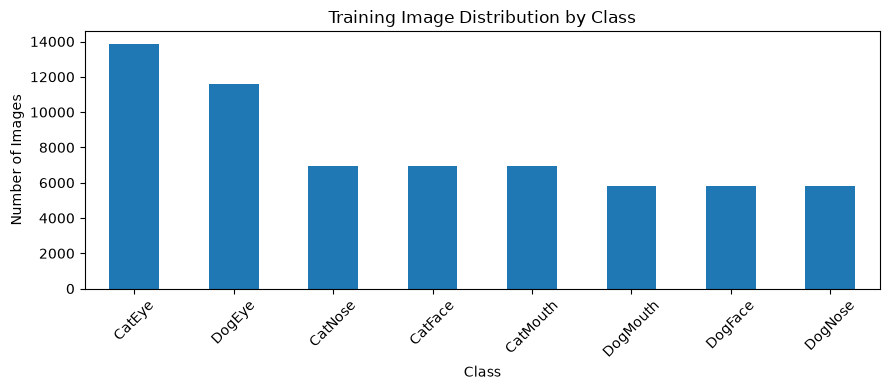

In [6]:
import matplotlib.pyplot as plt

class_counts.plot(kind="bar", figsize=(9, 4))
plt.title("Training Image Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

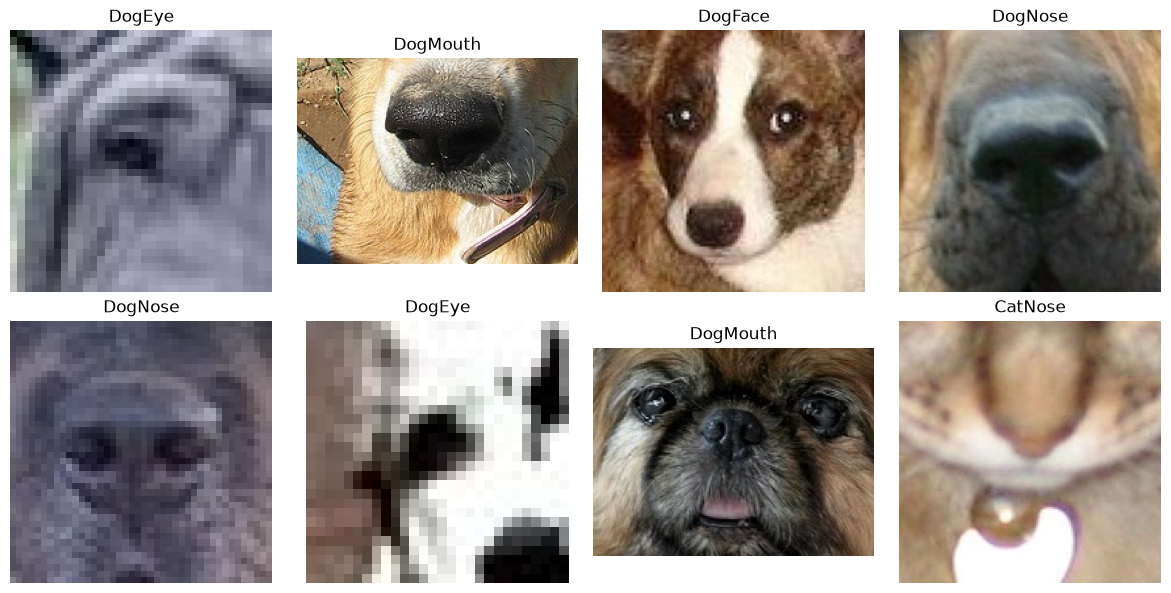

In [7]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

train_dir = Path("../data/train/train")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (_, row) in zip(axes.flat, df.head(8).iterrows()):
    image_path = train_dir / f"{row['image_id']}.jpg"
    image = Image.open(image_path)
    ax.imshow(image)
    ax.set_title(row["class"])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
image_sizes = []

for image_id in df["image_id"].head(100):
    image_path = train_dir / f"{image_id}.jpg"

    with Image.open(image_path) as image:
        image_sizes.append(image.size)

print("Different image dimensions:", set(image_sizes))

Different image dimensions: {(256, 288), (56, 56), (70, 70), (52, 52), (116, 116), (38, 38), (20, 20), (94, 70), (112, 112), (176, 176), (176, 124), (66, 66), (54, 40), (130, 130), (140, 140), (34, 34), (48, 48), (64, 47), (64, 44), (158, 158), (171, 210), (30, 30), (62, 62), (104, 77), (166, 116), (316, 222), (108, 108), (26, 26), (86, 86), (112, 163), (94, 66), (191, 191), (68, 50), (40, 40), (34, 24), (178, 178), (114, 114), (68, 68), (149, 148), (132, 132), (207, 232), (36, 36), (54, 54), (100, 100), (110, 110), (78, 54), (32, 32), (96, 96), (128, 128), (64, 64), (122, 90), (266, 266), (158, 117), (387, 388), (188, 182), (60, 60), (82, 82), (343, 376), (78, 78), (182, 135), (478, 585), (24, 24), (97, 97), (106, 106), (98, 68), (142, 105), (28, 28), (74, 74), (155, 154), (157, 157), (250, 358), (148, 148), (50, 37), (90, 64), (214, 157), (42, 42)}


In [9]:
missing_images = [
    image_id for image_id in df["image_id"]
    if not (train_dir / f"{image_id}.jpg").exists()
]

print("Missing training images:", len(missing_images))

Missing training images: 0


## 2. Data Preprocessing

### 2.1 Training and Validation Split

In [10]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["class"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

Training images: 50928
Validation images: 12732


In [11]:
import tensorflow as tf

class_names = sorted(df["class"].unique())
class_to_index = {name: i for i, name in enumerate(class_names)}

train_paths = [str(train_dir / f"{image_id}.jpg") for image_id in train_df["image_id"]]
val_paths = [str(train_dir / f"{image_id}.jpg") for image_id in val_df["image_id"]]

train_labels = train_df["class"].map(class_to_index).to_numpy()
val_labels = val_df["class"].map(class_to_index).to_numpy()

print(class_to_index)
print("Training paths:", len(train_paths))
print("Validation paths:", len(val_paths))

{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
Training paths: 50928
Validation paths: 12732


In [12]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, 128, 128)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))

train_ds = train_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [13]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))

Images shape: (32, 128, 128, 3)
Labels shape: (32,)
Pixel range: 0.0 1.0


## 3. CNN Model Development
### 3.1 Baseline CNN

In [14]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(8, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,672 (12.61 MB)

 Trainable params: 3,305,672 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### 3.2 Compile and Train Baseline CNN

In [15]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [16]:
train_ds = train_ds.shuffle(5000, seed=42)

In [17]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5


/Users/chaimaoueslati/Desktop/Data ENG and AI/data_ai_foundations/facial_feature_classifier/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 267s 162ms/step - accuracy: 0.9266 - loss: 0.2282 - val_accuracy: 0.9665 - val_loss: 0.1060
Epoch 2/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 249s 151ms/step - accuracy: 0.9729 - loss: 0.0825 - val_accuracy: 0.9779 - val_loss: 0.0709
Epoch 3/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 238s 146ms/step - accuracy: 0.9843 - loss: 0.0462 - val_accuracy: 0.9732 - val_loss: 0.0849
Epoch 4/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 234s 143ms/step - accuracy: 0.9884 - loss: 0.0339 - val_accuracy: 0.9728 - val_loss: 0.0998
Epoch 5/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 230s 141ms/step - accuracy: 0.9915 - loss: 0.0232 - val_accuracy: 0.9732 - val_loss: 0.1216


### Experiment 1: Baseline 

**Configuration**
- Input image size: 128 × 128 × 3
- Batch size: 32
- 3 convolutional layers (32, 64, 128 filters), max pooling, flatten, dense layer (128 neurons), softmax output (8 classes)
- Optimiser: Adam
- Learning rate: 0.001
- Loss function: Sparse categorical crossentropy
- Epochs: 5
- Training images: 50,928
- Validation images: 12,732

**Results**
| Epoch | Train accuracy | Validation accuracy | Train loss | Validation loss |
|---|---|---|---|---|
| 1 | 92.66% | 96.65% | 0.2282 | 0.1060 |
| 2 | 97.29% | 97.79% | 0.0825 | 0.0709 |
| 3 | 98.43% | 97.32% | 0.0462 | 0.0849 |
| 4 | 98.84% | 97.28% | 0.0339 | 0.0998 |
| 5 | 99.15% | 97.32% | 0.0232 | 0.1216 |

Epoch 2 had the highest validation accuracy and lowest validation loss in this run. Later epochs continued to improve training performance while validation loss increased.



In [18]:
import numpy as np

val_probabilities = model.predict(val_ds)
val_predictions = np.argmax(val_probabilities, axis=1)

398/398 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step


In [19]:
from sklearn.metrics import classification_report

print(classification_report(
    val_labels,
    val_predictions,
    target_names=class_names
))

              precision    recall  f1-score   support

      CatEye       0.95      0.99      0.97      2777
     CatFace       0.97      0.99      0.98      1388
    CatMouth       0.99      1.00      0.99      1388
     CatNose       0.98      0.93      0.96      1389
      DogEye       0.97      0.95      0.96      2316
     DogFace       0.99      0.97      0.98      1158
    DogMouth       1.00      1.00      1.00      1158
     DogNose       0.98      0.96      0.97      1158

    accuracy                           0.97     12732
   macro avg       0.98      0.97      0.98     12732
weighted avg       0.97      0.97      0.97     12732



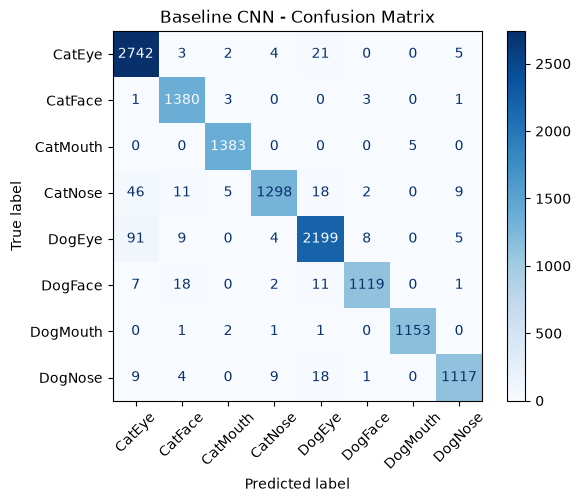

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    val_labels,
    val_predictions,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Baseline CNN - Confusion Matrix")
plt.show()

In [21]:
sample_submission = pd.read_csv(
    "../data/sample_submission.csv",
    dtype={"image_id": str}
)

print(sample_submission.shape)
print(sample_submission.head())

(29443, 2)
  image_id     class
0        1    DogEye
1        2   CatNose
2        3   CatNose
3        4   DogFace
4        5  DogMouth


In [25]:
test_dir = Path("../data/test/test")
test_paths = []

for image_id in sample_submission["image_id"]:
    filename = f"{int(image_id):05d}.jpg"
    full_path = test_dir / filename
    test_paths.append(str(full_path))

print(test_paths[:5])

['../data/test/test/00001.jpg', '../data/test/test/00002.jpg', '../data/test/test/00003.jpg', '../data/test/test/00004.jpg', '../data/test/test/00005.jpg']


In [26]:
def load_test_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, 128, 128)
    image = tf.cast(image, tf.float32) / 255.0
    return image

test_ds = tf.data.Dataset.from_tensor_slices(test_paths)
test_ds = test_ds.map(load_test_image, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [27]:
test_probabilities = model.predict(test_ds)
test_predictions = np.argmax(test_probabilities, axis=1)

print(test_probabilities.shape)
print(test_predictions.shape)

921/921 ━━━━━━━━━━━━━━━━━━━━ 38s 41ms/step
(29443, 8)
(29443,)


In [29]:
test_class_names = []

for i in test_predictions:
    test_class_names.append(class_names[i])

In [31]:
submission = sample_submission.copy()

submission["class"] = test_class_names

print(submission.shape)
print(submission.head())

submission.to_csv("../data/submission_baseline.csv", index=False)

(29443, 2)
  image_id     class
0        1    DogEye
1        2  DogMouth
2        3   DogNose
3        4   DogFace
4        5  CatMouth


In [32]:
print(class_names)
print(submission["class"].unique())

['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']
<StringArray>
[  'DogEye', 'DogMouth',  'DogNose',  'DogFace', 'CatMouth',  'CatFace',
   'CatEye',  'CatNose']
Length: 8, dtype: str


In [33]:
print(sample_submission.head(10))
print(sample_submission["class"].unique())

  image_id     class
0        1    DogEye
1        2   CatNose
2        3   CatNose
3        4   DogFace
4        5  DogMouth
5        6   CatNose
6        7  CatMouth
7        8    DogEye
8        9  DogMouth
9       10   CatFace
<StringArray>
[  'DogEye',  'CatNose',  'DogFace', 'DogMouth', 'CatMouth',  'CatFace',
  'DogNose',   'CatEye']
Length: 8, dtype: str


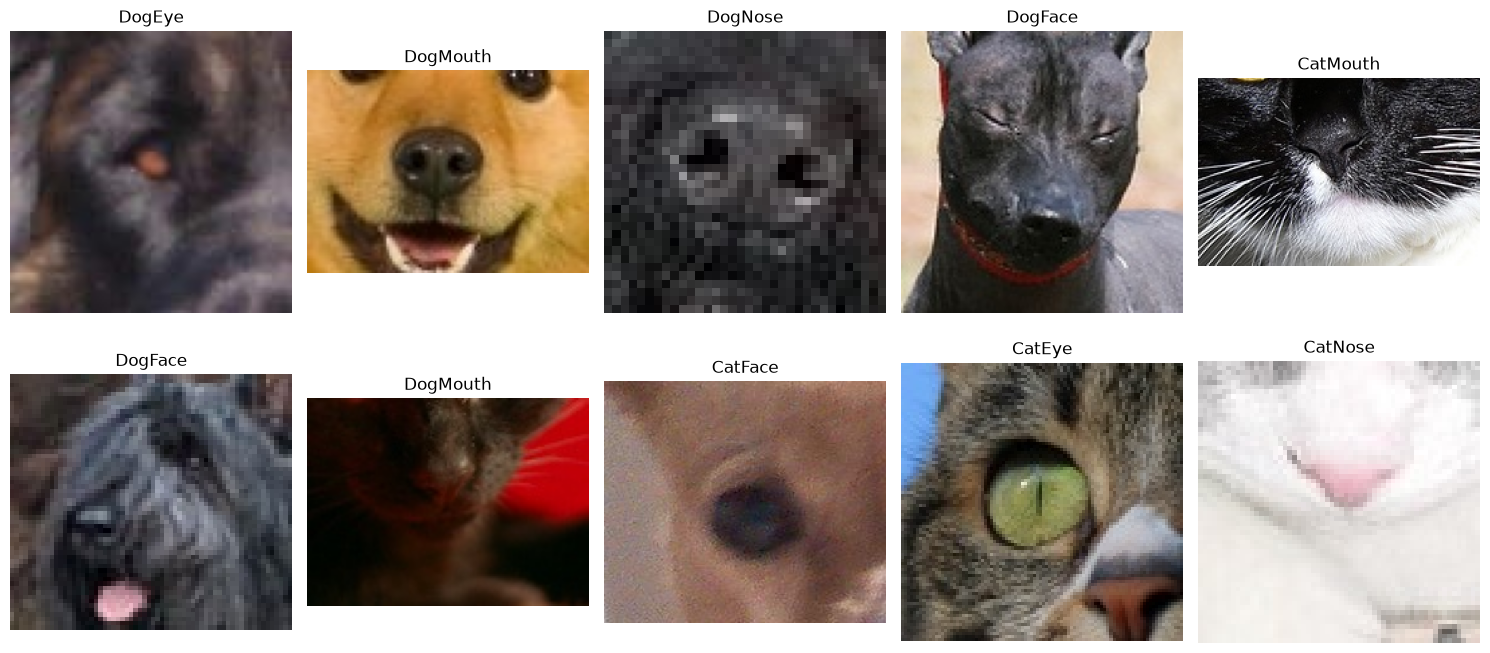

In [35]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, ax in enumerate(axes.flat):
    image = plt.imread(test_paths[i])
    ax.imshow(image)
    ax.set_title(test_class_names[i])
    ax.axis("off")

plt.tight_layout()
plt.show()

## Experiment 2: Transfer Learning with MobileNetV2

**Objective:** Investigate whether a pretrained MobileNetV2 model improves image classification compared with the baseline CNN.

- Use MobileNetV2 with pretrained ImageNet weights.
- Freeze the pretrained layers and train a new classifier for our eight classes.

**Initial settings:**
- Image size: 128 × 128
- Batch size: 32
- Optimizer: Adam
- Learning rate: 0.001
- Maximum epochs: 5
- Dropout: 0.3
- Early stopping patience: 2

In [36]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def load_mobilenet_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, 128, 128)
    image = preprocess_input(image)
    return image, label

train_ds2 = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_ds2 = train_ds2.shuffle(5000, seed=42)
train_ds2 = train_ds2.map(load_mobilenet_image, num_parallel_calls=tf.data.AUTOTUNE)
train_ds2 = train_ds2.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds2 = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_ds2 = val_ds2.map(load_mobilenet_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds2 = val_ds2.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [37]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

base_model.trainable = False

model2 = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(8, activation="softmax")
])

model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model2.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,984 (9.24 MB)

 Trainable params: 165,000 (644.53 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [38]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history2 = model2.fit(
    train_ds2,
    validation_data=val_ds2,
    epochs=5,
    callbacks=[early_stopping]
)

val_loss2, val_accuracy2 = model2.evaluate(val_ds2)

print("Experiment 2 validation accuracy:", val_accuracy2)

Epoch 1/5


/Users/chaimaoueslati/Desktop/Data ENG and AI/data_ai_foundations/facial_feature_classifier/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 182s 113ms/step - accuracy: 0.9214 - loss: 0.2243 - val_accuracy: 0.9583 - val_loss: 0.1189
Epoch 2/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 172s 108ms/step - accuracy: 0.9541 - loss: 0.1310 - val_accuracy: 0.9641 - val_loss: 0.1026
Epoch 3/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 179s 112ms/step - accuracy: 0.9612 - loss: 0.1077 - val_accuracy: 0.9625 - val_loss: 0.1107
Epoch 4/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 186s 117ms/step - accuracy: 0.9675 - loss: 0.0911 - val_accuracy: 0.9642 - val_loss: 0.1090
398/398 ━━━━━━━━━━━━━━━━━━━━ 32s 81ms/step - accuracy: 0.9641 - loss: 0.1026
Experiment 2 validation accuracy: 0.9641062021255493


In [40]:
model2.save("../data/mobilenet_v2.keras")

In [39]:
def load_mobilenet_test_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, 128, 128)
    image = preprocess_input(image)
    return image

test_ds2 = tf.data.Dataset.from_tensor_slices(test_paths)
test_ds2 = test_ds2.map(load_mobilenet_test_image, num_parallel_calls=tf.data.AUTOTUNE)
test_ds2 = test_ds2.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_probabilities2 = model2.predict(test_ds2)
test_predictions2 = np.argmax(test_probabilities2, axis=1)

test_class_names2 = []
for i in test_predictions2:
    test_class_names2.append(class_names[i])

submission2 = sample_submission.copy()
submission2["class"] = test_class_names2
submission2.to_csv("../data/submission_mobilenet.csv", index=False)

print(submission2.shape)
print(submission2.head())

921/921 ━━━━━━━━━━━━━━━━━━━━ 80s 86ms/step
(29443, 2)
  image_id     class
0        1    DogEye
1        2  DogMouth
2        3   DogNose
3        4   DogFace
4        5  CatMouth


### Experiment 2 Results

- Training completed: 4 epochs 
- Best epoch by validation loss: 2
- Validation accuracy: 96.41%
- Validation loss: 0.1026
- Kaggle accuracy: Pending